Cell 1: Setup and Kaggle API Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import gc

# 1. Check if the extracted files are still in your folder
if not os.path.exists('train.csv') or not os.path.exists('test.csv'):
    print("Error: CSV files not found. Did you accidentally delete them?")
else:
    print("Files found! Loading data safely...")

    # 2. Define strict memory types to prevent OOM crashes
    dtypes = {
        'vendor_id': 'int8',
        'passenger_count': 'int8',
        'pickup_longitude': 'float32',
        'pickup_latitude': 'float32',
        'dropoff_longitude': 'float32',
        'dropoff_latitude': 'float32',
        'store_and_fwd_flag': 'category',
        'trip_duration': 'int32'
    }

    cols_to_use = list(dtypes.keys()) + ['pickup_datetime']
    test_cols = [c for c in cols_to_use if c != 'trip_duration']

    # 3. Load the data using only 50,000 rows
    train_df = pd.read_csv('train.csv', nrows=50000, usecols=cols_to_use, dtype=dtypes)
    test_df = pd.read_csv('test.csv', nrows=10000, usecols=test_cols)

    # 4. Clean anomalies
    train_df = train_df[(train_df['trip_duration'] < 500000) & (train_df['trip_duration'] > 10)]
    train_df = train_df[train_df['passenger_count'] > 0]

    gc.collect() # Free up memory
    
    print(f"Ready to go! Train shape: {train_df.shape}")


Files found! Loading data safely...
Ready to go! Train shape: (49929, 9)


Cell 2: Imports and AWS SageMaker Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import sagemaker
from sagemaker import get_execution_role
import boto3
import os

# SageMaker Session Setup
sagemaker_session = sagemaker.Session()
role = get_execution_role()
bucket = sagemaker_session.default_bucket()
prefix = 'nyc-taxi-duration'

print(f"Sagemaker Role: {role}")
print(f"S3 Bucket: {bucket}/{prefix}")

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


/opt/conda/lib/python3.12/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


Sagemaker Role: arn:aws:iam::749178829549:role/LabRole
S3 Bucket: sagemaker-us-east-1-749178829549/nyc-taxi-duration


Cell 3: Load Data & Exploratory Data Analysis (EDA)

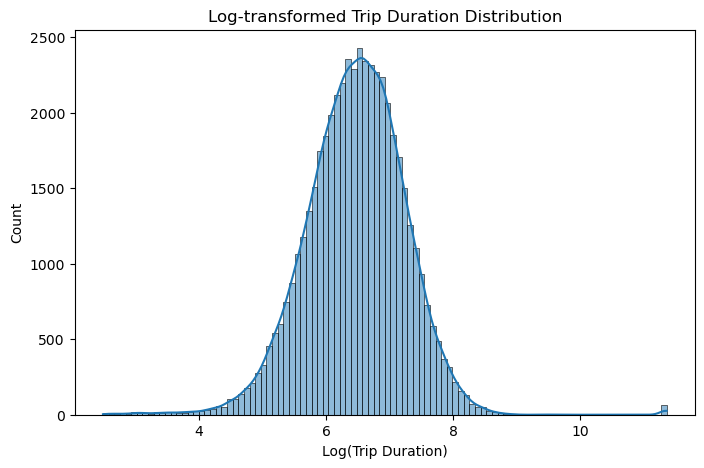

In [3]:
# Visualize Trip Duration distribution (Log scale)
plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(train_df['trip_duration']), bins=100, kde=True)
plt.title('Log-transformed Trip Duration Distribution')
plt.xlabel('Log(Trip Duration)')
plt.show()

Cell 4: Feature Engineering

In [4]:
def haversine_distance(lat1, lon1, lat2, lon2):
    # Calculate distance between two coordinates
    R = 6371  # Earth radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

def engineer_features(df):
    df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
    df['month'] = df['pickup_datetime'].dt.month
    df['day_of_week'] = df['pickup_datetime'].dt.dayofweek
    df['hour'] = df['pickup_datetime'].dt.hour

    # Distance feature
    df['distance_km'] = haversine_distance(
        df['pickup_latitude'], df['pickup_longitude'],
        df['dropoff_latitude'], df['dropoff_longitude']
    )

    # Encode categorical flags
    if 'store_and_fwd_flag' in df.columns:
        df['store_and_fwd_flag'] = df['store_and_fwd_flag'].map({'Y': 1, 'N': 0})

    return df

print("Engineering features for train...")
train_df = engineer_features(train_df)
print("Engineering features for test...")
test_df = engineer_features(test_df)

Engineering features for train...
Engineering features for test...


Cell 5: Data Preparation for SageMaker XGBoost

In [5]:
# Select features
features = ['vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude',
            'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
            'month', 'day_of_week', 'hour', 'distance_km']

# We predict Log(Trip Duration) to penalize errors evenly
X = train_df[features]
y = np.log1p(train_df['trip_duration'])

# Train / Validation Split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# SageMaker expects the target variable in the first column for CSV
train_sagemaker = pd.concat([y_train, X_train], axis=1)
val_sagemaker = pd.concat([y_val, X_val], axis=1)

# Save locally
train_sagemaker.to_csv('train_xgb.csv', index=False, header=False)
val_sagemaker.to_csv('val_xgb.csv', index=False, header=False)

# Upload to S3
train_path = sagemaker_session.upload_data('train_xgb.csv', bucket=bucket, key_prefix=f'{prefix}/train')
val_path = sagemaker_session.upload_data('val_xgb.csv', bucket=bucket, key_prefix=f'{prefix}/val')

print(f"Train data in S3: {train_path}")
print(f"Val data in S3: {val_path}")

Train data in S3: s3://sagemaker-us-east-1-749178829549/nyc-taxi-duration/train/train_xgb.csv
Val data in S3: s3://sagemaker-us-east-1-749178829549/nyc-taxi-duration/val/val_xgb.csv


Cell 6: Train SageMaker XGBoost Model

In [6]:
from sagemaker.image_uris import retrieve

# Get SageMaker XGBoost Image
container = retrieve("xgboost", boto3.Session().region_name, "1.5-1")

xgb = sagemaker.estimator.Estimator(
    image_uri=container,
    role=role,
    instance_count=1,
    instance_type='ml.m5.xlarge',
    output_path=f's3://{bucket}/{prefix}/output',
    sagemaker_session=sagemaker_session
)

xgb.set_hyperparameters(
    max_depth=8,
    eta=0.1,
    gamma=4,
    min_child_weight=6,
    subsample=0.8,
    objective='reg:squarederror',
    num_round=100  # Increase to 300+ for better accuracy
)

s3_input_train = sagemaker.inputs.TrainingInput(s3_data=train_path, content_type='csv')
s3_input_val = sagemaker.inputs.TrainingInput(s3_data=val_path, content_type='csv')

# Train the model
xgb.fit({'train': s3_input_train, 'validation': s3_input_val})

/opt/conda/lib/python3.12/site-packages/sagemaker/estimator.py:588: SageMakerV2DeprecationWarning: Estimator is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelTrainer` (`from sagemaker.train import ModelTrainer`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
Estimator is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelTrainer` (`from sagemaker.train import ModelTrainer`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
INFO:sagemaker:Creating training-job with name: sagemaker-xgboost-2026-10-18-12-51-53-318


2026-10-18 12:51:54 Starting - Starting the training job...
2026-10-18 12:52:09 Starting - Preparing the instances for training...
2026-10-18 12:52:38 Downloading - Downloading input data...
2026-10-18 12:53:08 Downloading - Downloading the training image...
2026-10-18 12:53:44 Training - Training image download completed. Training in progress../miniconda3/lib/python3.8/site-packages/xgboost/compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index
[2026-10-18 12:53:53.531 ip-10-0-138-14.ec2.internal:7 INFO utils.py:28] RULE_JOB_STOP_SIGNAL_FILENAME: None
[2026-10-18 12:53:53.553 ip-10-0-138-14.ec2.internal:7 INFO profiler_config_parser.py:111] User has disabled profiler.
[2026-10-18:12:53:53:INFO] Imported framework sagemaker_xgboost_container.training
[2026-10-18:12:53:53:INFO] Failed to parse hyperparameter objective value reg:squar

Cell 7: Model Deployment & Inference

In [10]:
import os
os.environ["SAGEMAKER_SUPPRESS_V2_WARNING"]="0"

In [12]:
# Deploy the endpoint
xgb_predictor = xgb.deploy(
    initial_instance_count=1,
    instance_type='ml.m5.xlarge',
    serializer=sagemaker.serializers.CSVSerializer(),
    deserializer=sagemaker.deserializers.CSVDeserializer()
)

# Test the endpoint with validation data
sample_val = X_val.head(10).to_csv(header=False, index=False).strip('\n').split('\n')
predictions = []

for row in sample_val:
    pred = float(xgb_predictor.predict(row)[0][0])
    # Convert log prediction back to seconds
    predictions.append(np.expm1(pred))

print("Predicted Durations (seconds):", [round(p, 2) for p in predictions])

INFO:sagemaker:Creating model with name: sagemaker-xgboost-2026-10-18-14-36-02-615
INFO:sagemaker:Creating endpoint-config with name sagemaker-xgboost-2026-10-18-14-36-02-615
INFO:sagemaker:Creating endpoint with name sagemaker-xgboost-2026-10-18-14-36-02-615


------!Predicted Durations (seconds): [1039.43, 540.55, 245.73, 382.88, 3907.3, 535.61, 948.99, 1657.96, 2174.66, 249.85]


Cell 8: Cleanup (Important to avoid AWS charges)

In [ ]:
# Delete the endpoint when you are done recording your video
xgb_predictor.delete_endpoint()